<a href="https://colab.research.google.com/github/danaz-py/pytorch_practice/blob/main/00_homemade_excercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Homemade Exercises

with the help of AI, of course.

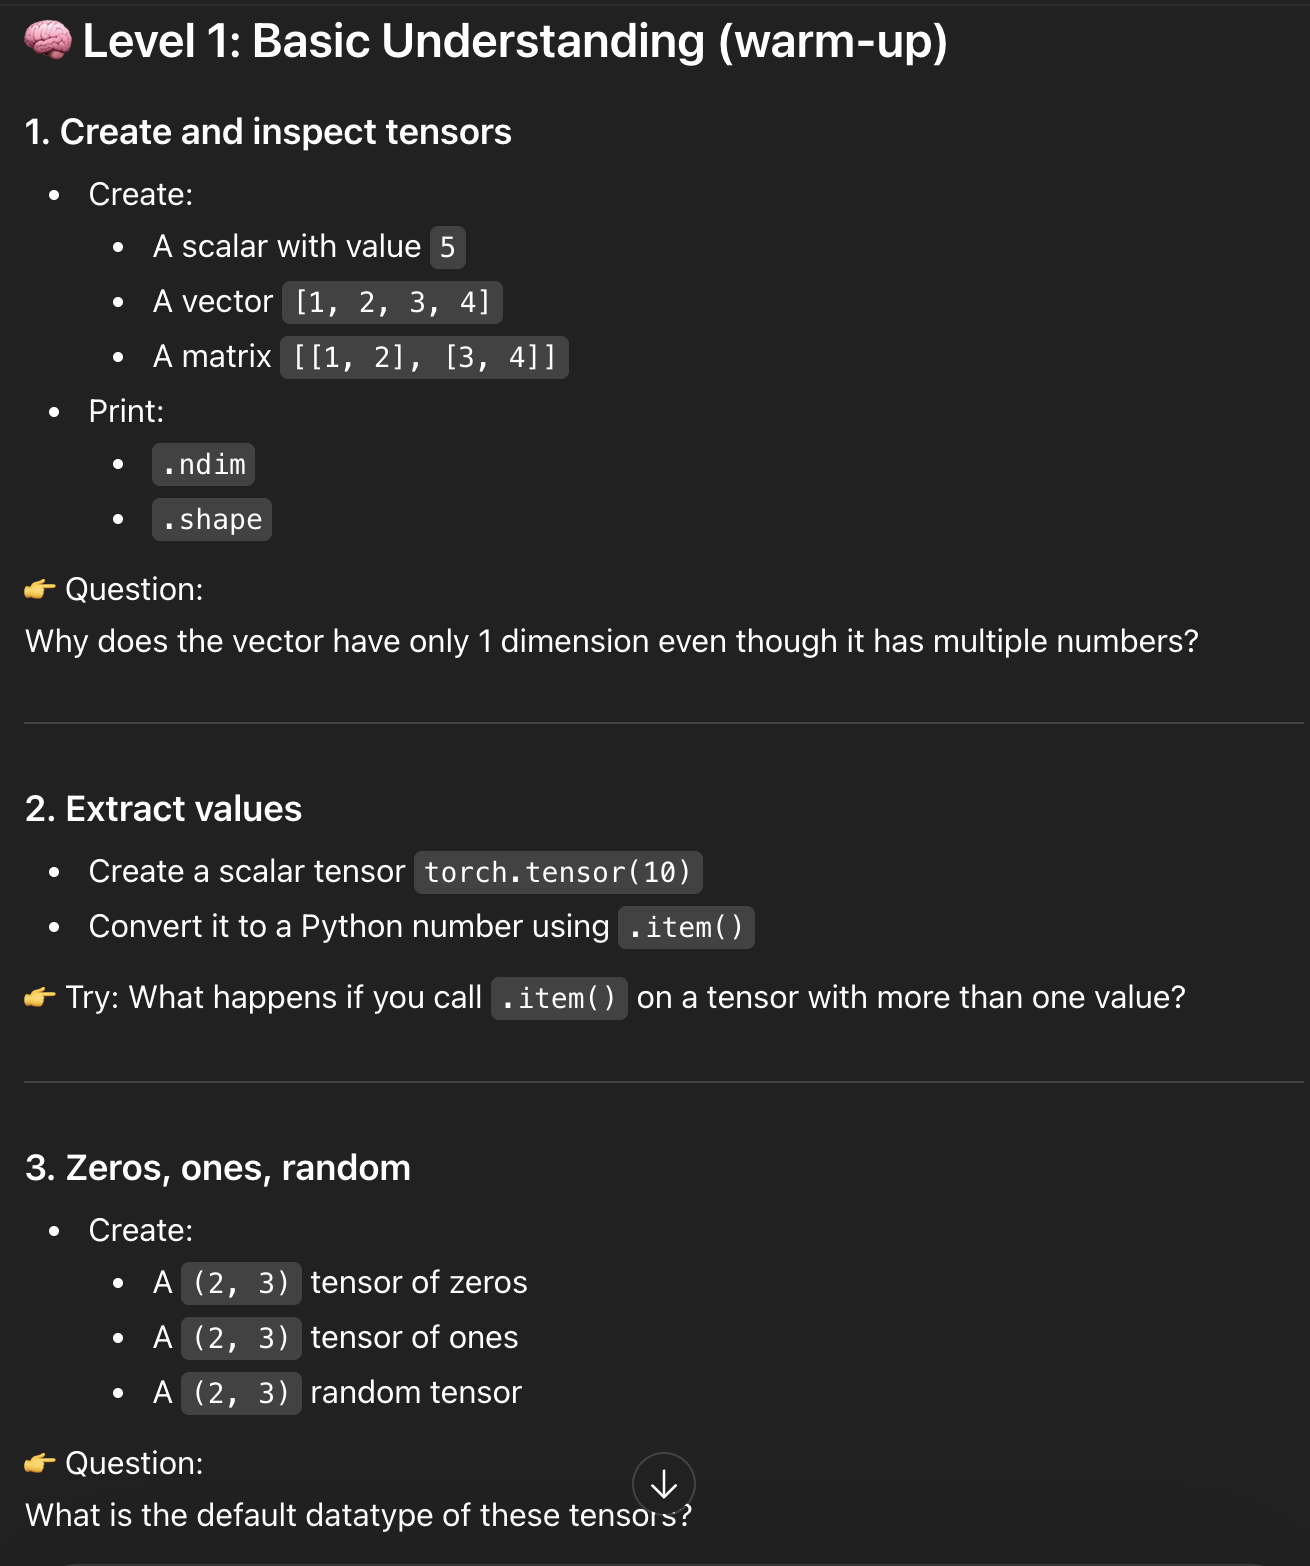

In [ ]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print(torch.__version__)

2.10.0+cpu


In [ ]:
#1.
scalar = torch.tensor(3)
print(scalar)
print(scalar.ndim)
print(scalar.shape)
print(scalar.dtype)


tensor(3)
0
torch.Size([])
torch.int64


In [ ]:
vector = torch.tensor([1,2,3,4])
print(vector)
print(vector.ndim)
print(vector.shape)

tensor([1, 2, 3, 4])
1
torch.Size([4])
torch.int64


In [ ]:
matrix = torch.tensor([[1, 2], [3, 4]])
print(matrix)
print(matrix.ndim)
print(matrix.shape)

tensor([[1, 2],
        [3, 4]])
2
torch.Size([2, 2])


A vector has only one dimension (1D) because it is a linear, sequential list of numbers.

In [ ]:
#2.
scalar = torch.tensor(10)
scalar = scalar.item()
print(scalar)
print(type(scalar))

10
<class 'int'>


In [ ]:
#What happens if you call .item() on a tensor with more than one value?
#using vector from above
vector.item()

RuntimeError: a Tensor with 4 elements cannot be converted to Scalar

In [ ]:
#3.
zeros = torch.zeros(2,3)
print(zeros)

tensor([[0., 0., 0.],
        [0., 0., 0.]])


In [ ]:
ones = torch.ones(2, 3)
ones

tensor([[1., 1., 1.],
        [1., 1., 1.]])

In [ ]:
random = torch.rand(2, 3)
random

tensor([[0.0137, 0.2416, 0.8954],
        [0.7309, 0.5277, 0.1313]])

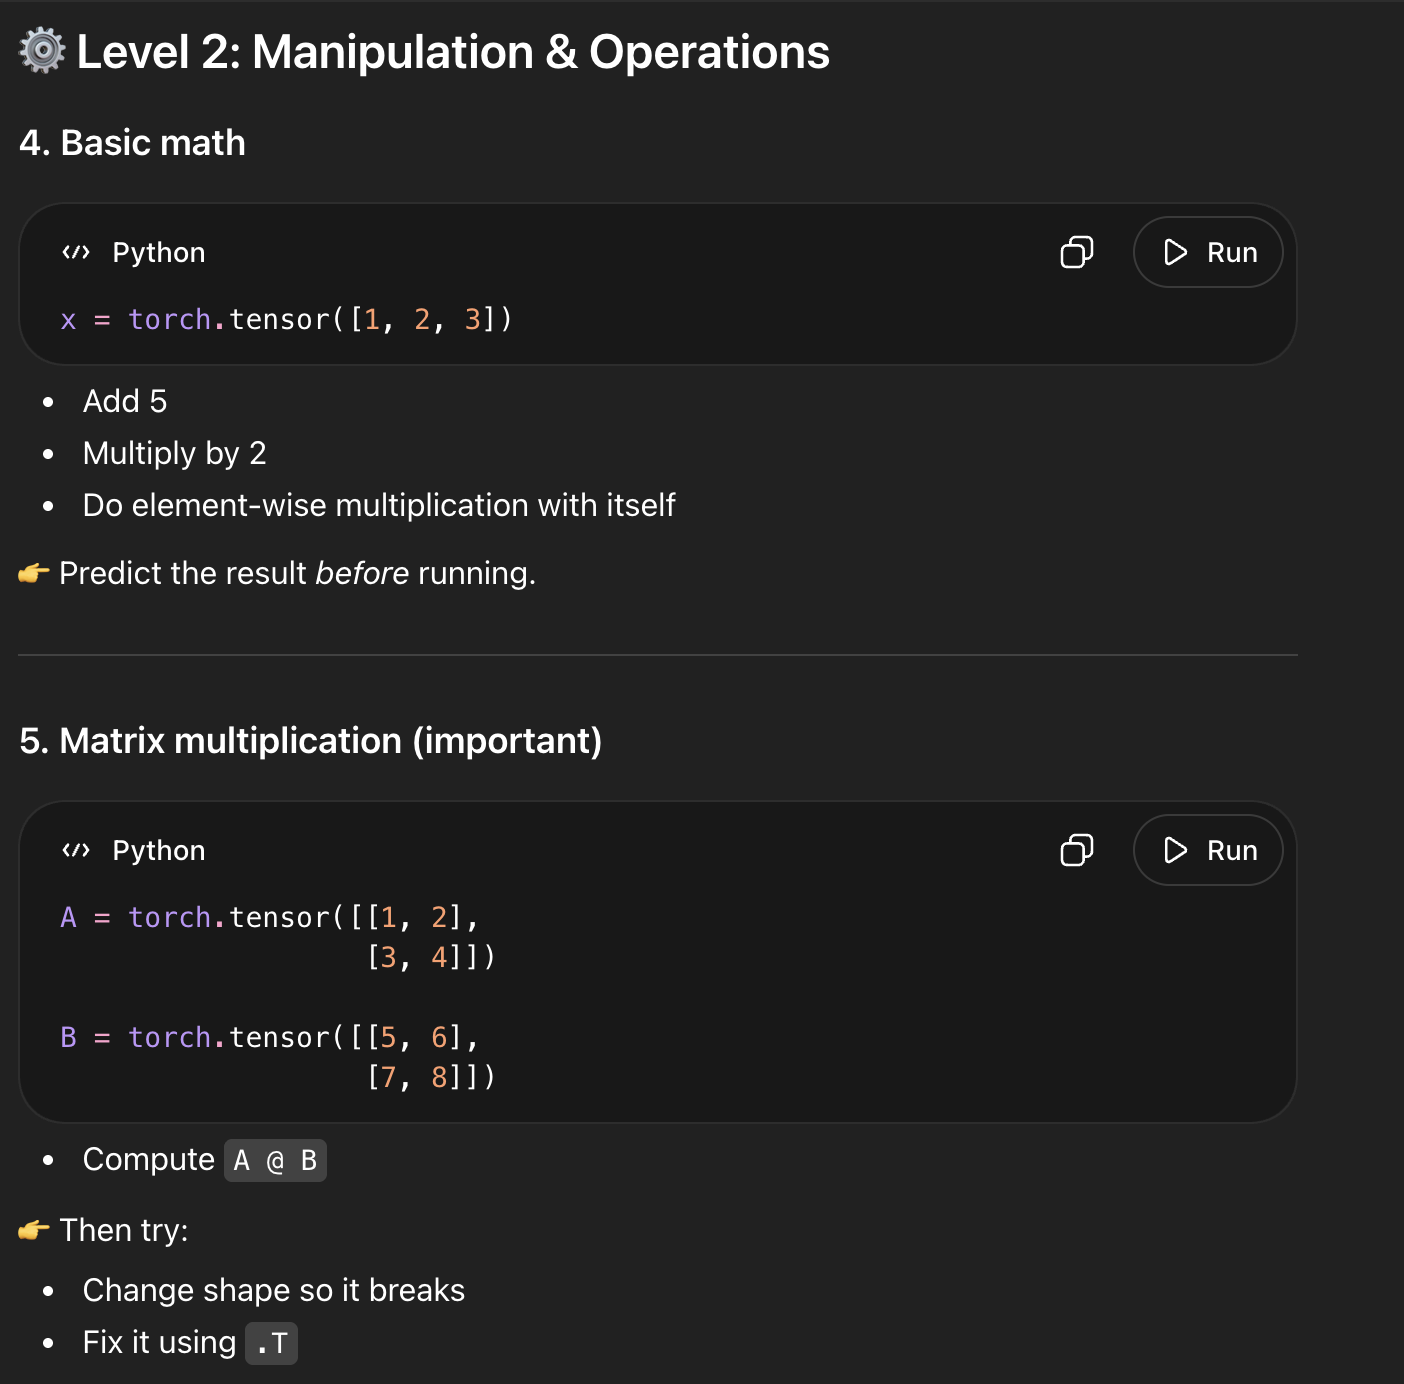
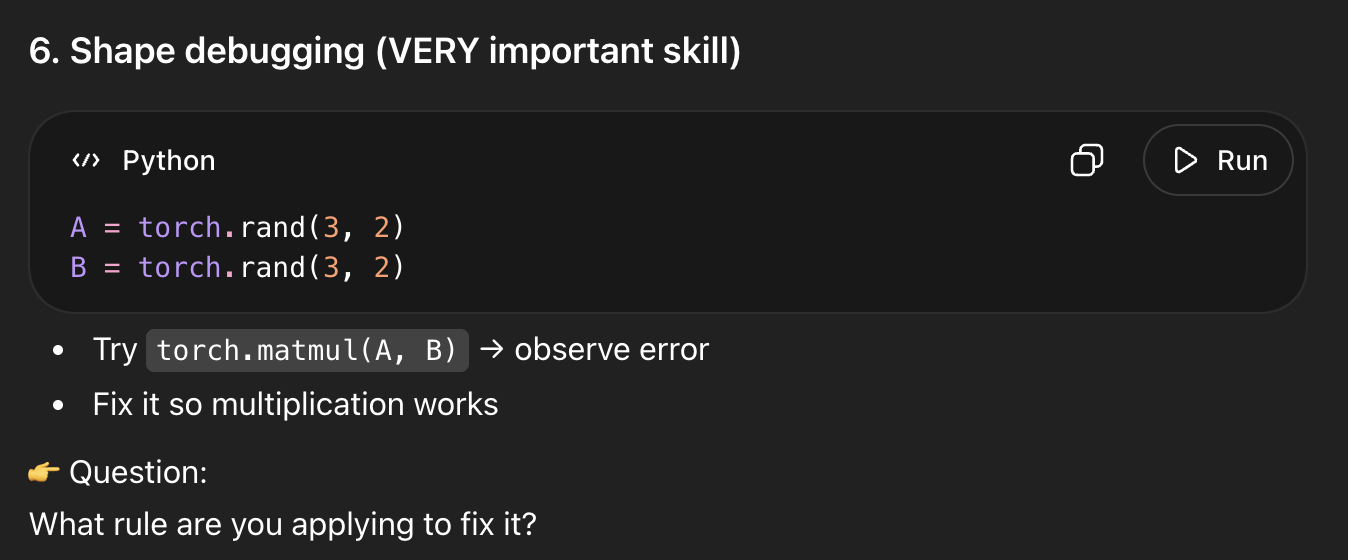

In [ ]:
#4.
x = torch.tensor([1, 2, 3])
#add 5
print(x + 5)

#multiply by 2
print(x*2)

#do element wise multiplciation w itself
print(x*x)

tensor([6, 7, 8])
tensor([2, 4, 6])
tensor([1, 4, 9])


In [ ]:
#5.
A = torch.tensor([[1,2],
                  [3, 4]])
B = torch.tensor([[5, 6],
                  [7, 8]])
torch.matmul(A, B)

tensor([[19, 22],
        [43, 50]])

In [ ]:
#now break it
B = B.reshape(1, 4)
print(B)
torch.matmul(A, B)

tensor([[5, 6, 7, 8]])


RuntimeError: mat1 and mat2 shapes cannot be multiplied (2x2 and 1x4)

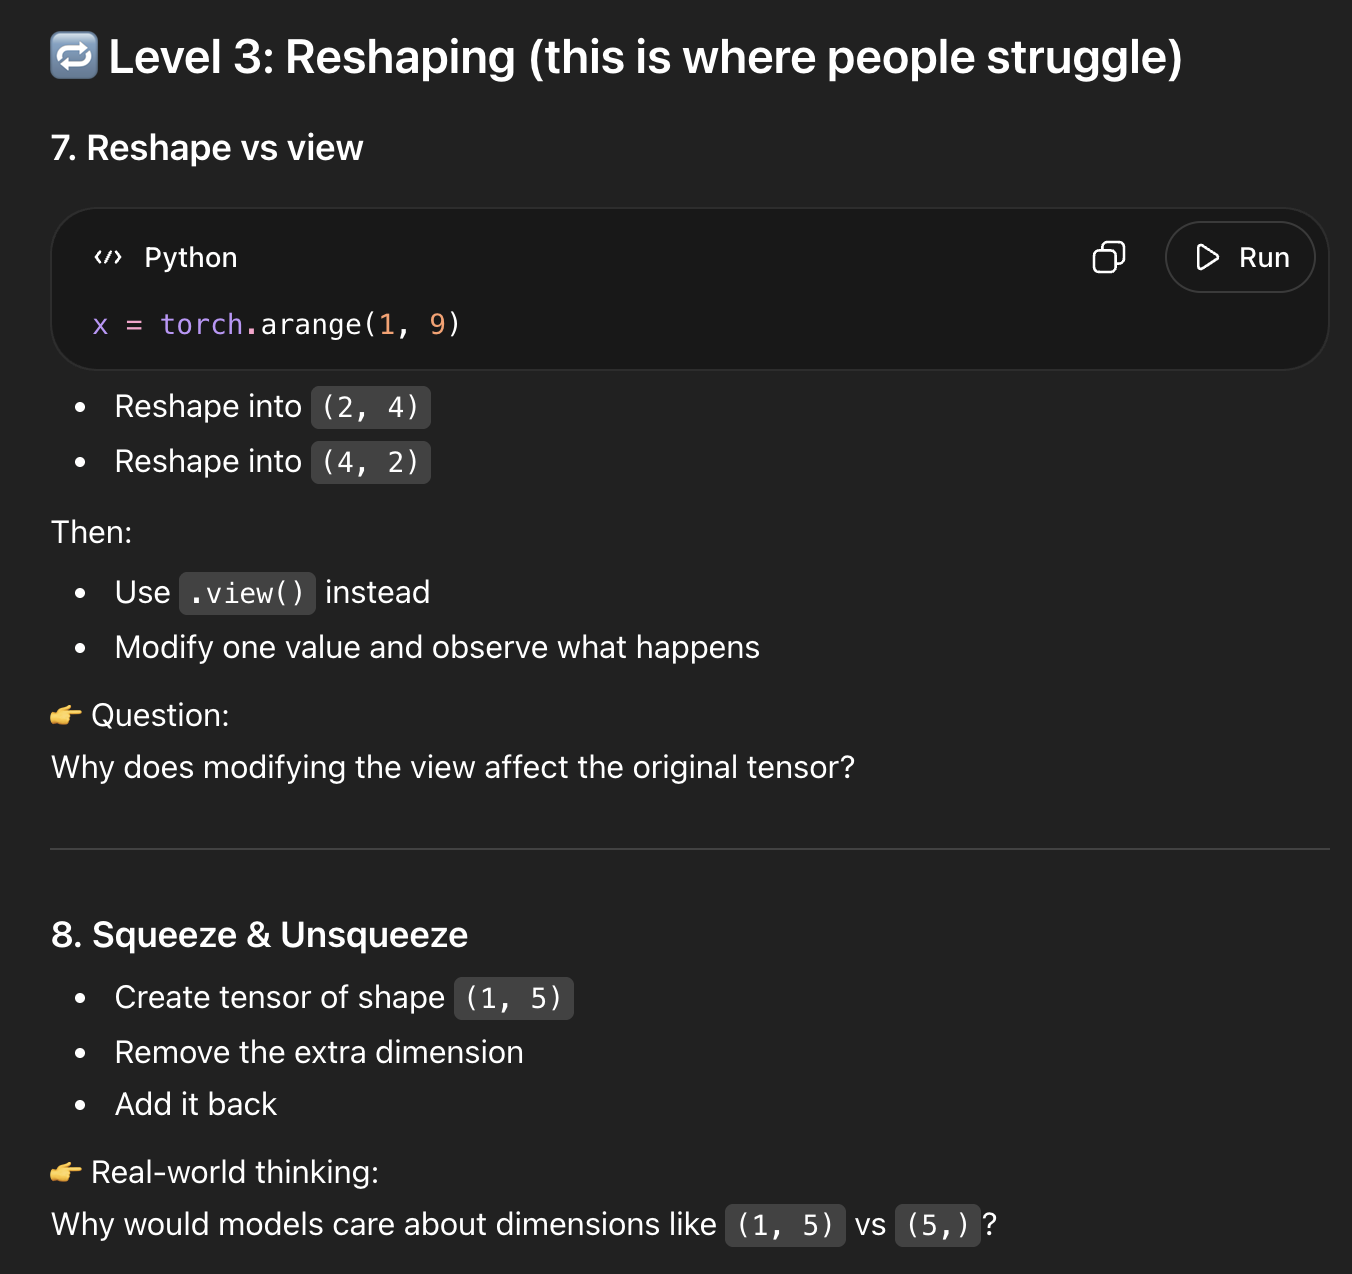
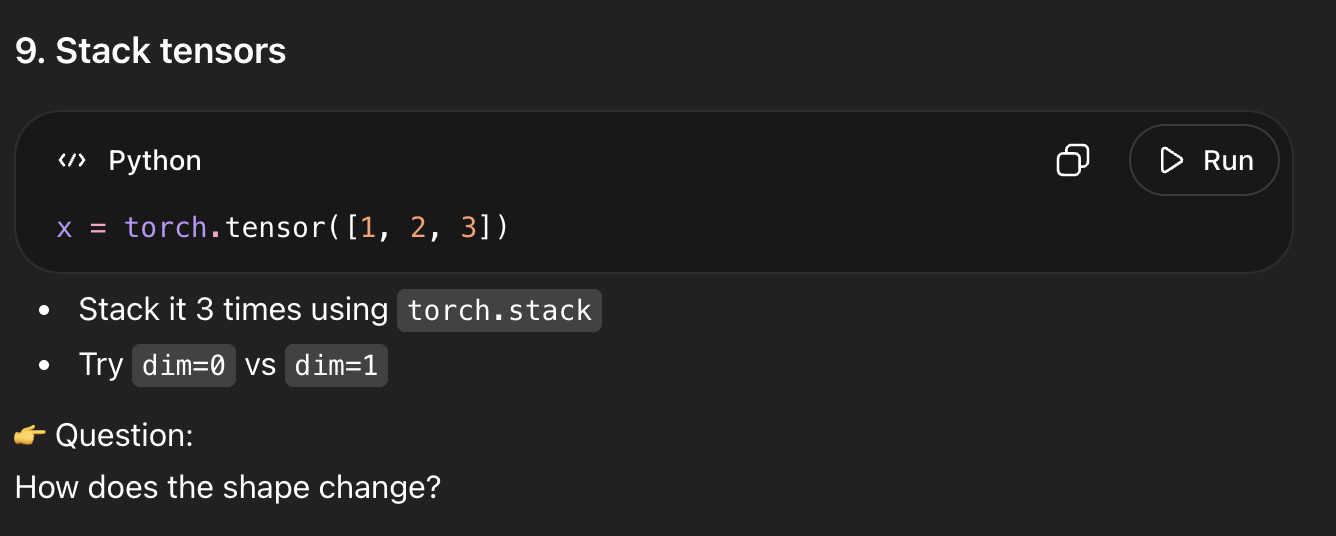

In [ ]:
#fuck 6 lets do 7
x = torch.arange(1, 9) #exlcusive it seems
x

tensor([1, 2, 3, 4, 5, 6, 7, 8])

In [ ]:
x.reshape(2, 4)

tensor([[1, 2, 3, 4],
        [5, 6, 7, 8]])

In [ ]:
x.reshape(4, 2)

tensor([[1, 2],
        [3, 4],
        [5, 6],
        [7, 8]])

In [ ]:
x.view(2, 4)
#no addiitonal memory, data sharing

tensor([[1, 2, 3, 4],
        [5, 6, 7, 8]])

In [ ]:
torch.manual_seed(8)
C = torch.rand(1,5)
C

tensor([[0.5979, 0.8453, 0.9464, 0.2965, 0.5138]])

In [ ]:
C.squeeze()

tensor([0.5979, 0.8453, 0.9464, 0.2965, 0.5138])

In [ ]:
C.unsqueeze()

In [ ]:
#9. https://docs.pytorch.org/docs/stable/generated/torch.stack.html
x = torch.tensor([1, 2, 3])
print(x)

#stack it 3 times

tensor([1, 2, 3])


In [ ]:
x = torch.stack((x, x, x), dim=0)
print(x)
print(x.shape)

tensor([[1, 2, 3],
        [1, 2, 3],
        [1, 2, 3]])
torch.Size([3, 3])


In [ ]:
x = torch.stack((x, x, x), dim=1)
print(x)
print(x.shape)

tensor([[[1, 2, 3],
         [1, 2, 3],
         [1, 2, 3]],

        [[1, 2, 3],
         [1, 2, 3],
         [1, 2, 3]],

        [[1, 2, 3],
         [1, 2, 3],
         [1, 2, 3]]])
torch.Size([3, 3, 3])


In [ ]:
x = torch.stack((x, x, x), dim=2)
print(x)
print(x.shape)

tensor([[[[1, 2, 3],
          [1, 2, 3],
          [1, 2, 3]],

         [[1, 2, 3],
          [1, 2, 3],
          [1, 2, 3]],

         [[1, 2, 3],
          [1, 2, 3],
          [1, 2, 3]]],


        [[[1, 2, 3],
          [1, 2, 3],
          [1, 2, 3]],

         [[1, 2, 3],
          [1, 2, 3],
          [1, 2, 3]],

         [[1, 2, 3],
          [1, 2, 3],
          [1, 2, 3]]],


        [[[1, 2, 3],
          [1, 2, 3],
          [1, 2, 3]],

         [[1, 2, 3],
          [1, 2, 3],
          [1, 2, 3]],

         [[1, 2, 3],
          [1, 2, 3],
          [1, 2, 3]]]])
torch.Size([3, 3, 3, 3])


Why would models care about dimensions like (1, 5) vs (5,)

so it can perform matrix multiplcaiton correctly

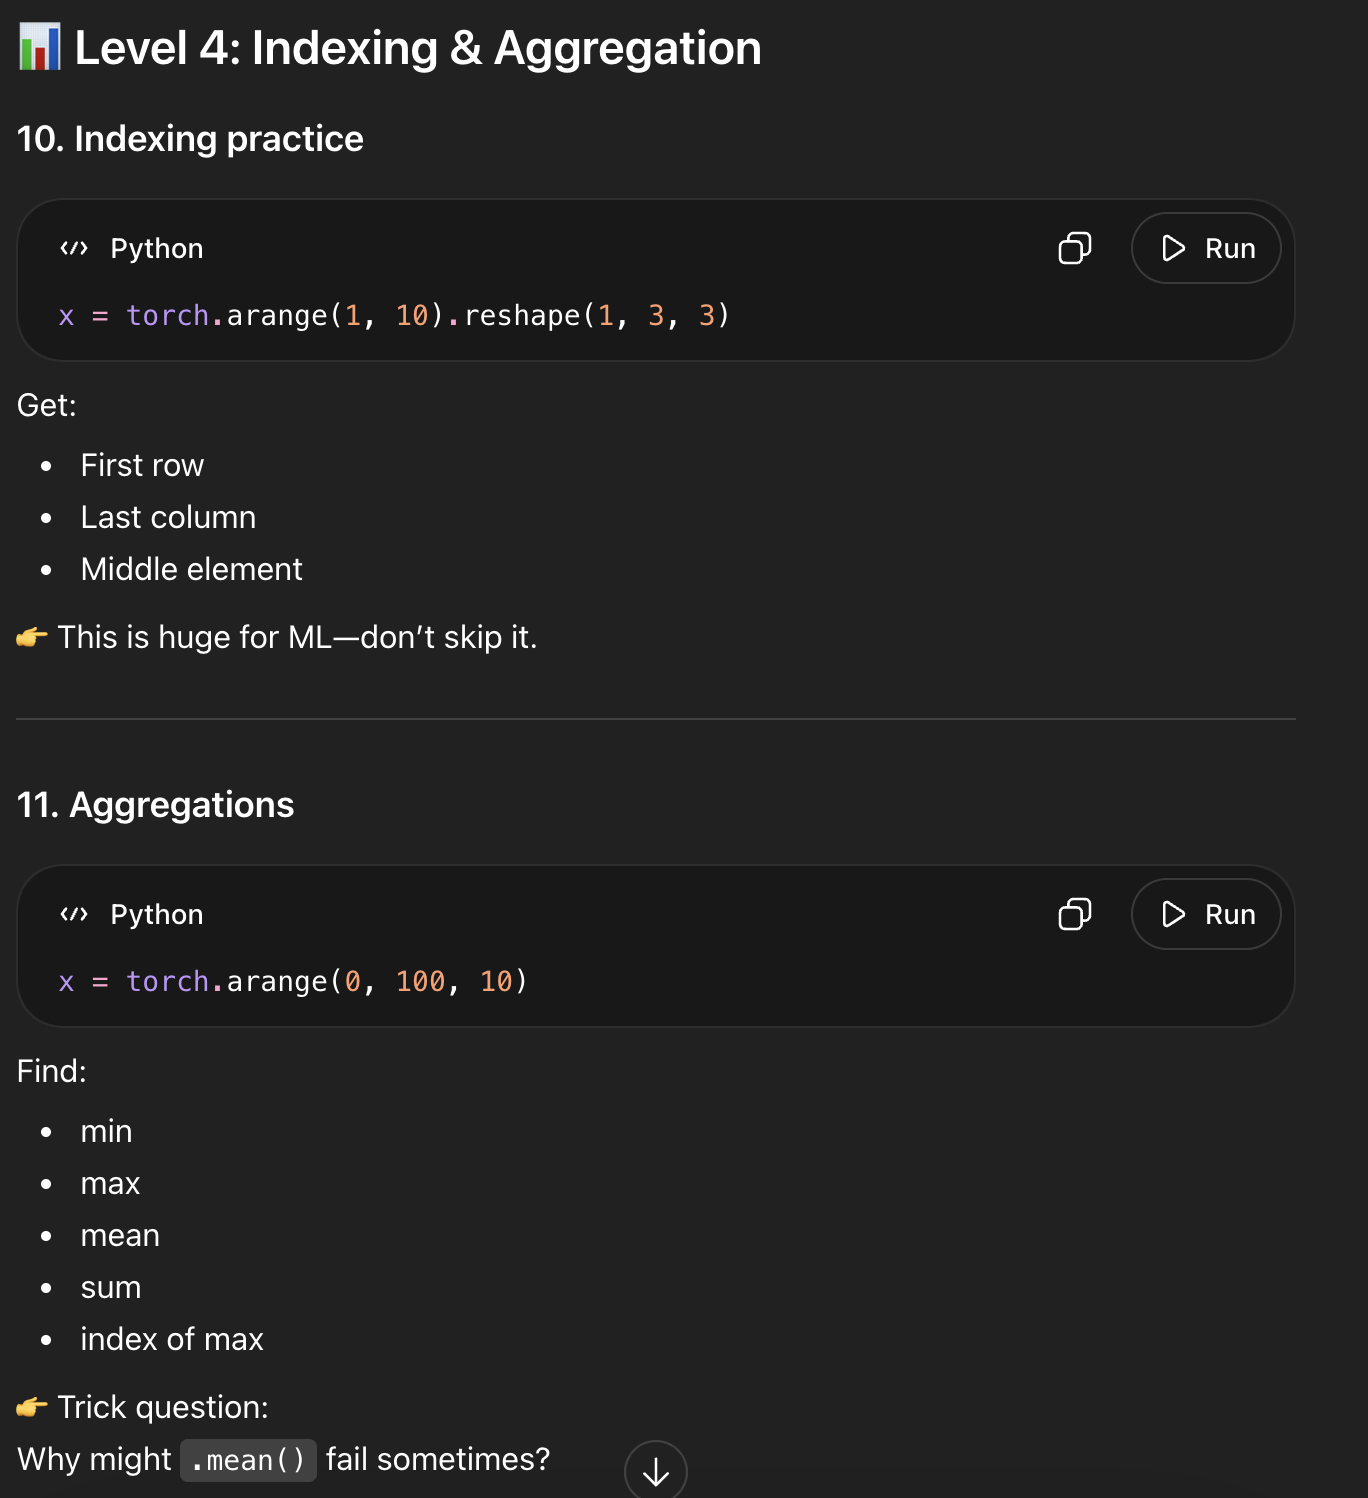

In [ ]:
#10.
x = torch.arange(1, 10).reshape(1, 3,3)
x

tensor([[[1, 2, 3],
         [4, 5, 6],
         [7, 8, 9]]])

In [ ]:
#first row
x[0][0]
#this is a vector not a matrix? NO. mistake
#there are 3 rows in this matrix and x[0] gets the first row and x[0][0] gets the first thing in tha trow

tensor([1, 2, 3])

In [ ]:
#last columns [3, 6, 9] GOT THIS WORNG
x[:, :, -1]
#all elements in first dimension, all rows, last colum = -1

tensor([[3, 6, 9]])

In [ ]:
#Middle elemnt [5]
x[0][1][1]

tensor(5)

In [ ]:
#11.
x=torch.arange(0, 100, 10)
x

tensor([ 0, 10, 20, 30, 40, 50, 60, 70, 80, 90])

In [ ]:
x.min()

tensor(0)

In [ ]:
x.max()

tensor(90)

In [ ]:
x.mean() #fails bc of wrong datatype

RuntimeError: mean(): could not infer output dtype. Input dtype must be either a floating point or complex dtype. Got: Long

In [ ]:
x.type(torch.float32).mean() #works with float 32 just not int64 which was what it was before

tensor(45.)

In [ ]:
x.sum()

tensor(450)

In [ ]:
#index of the max
x.argmax()

tensor(9)

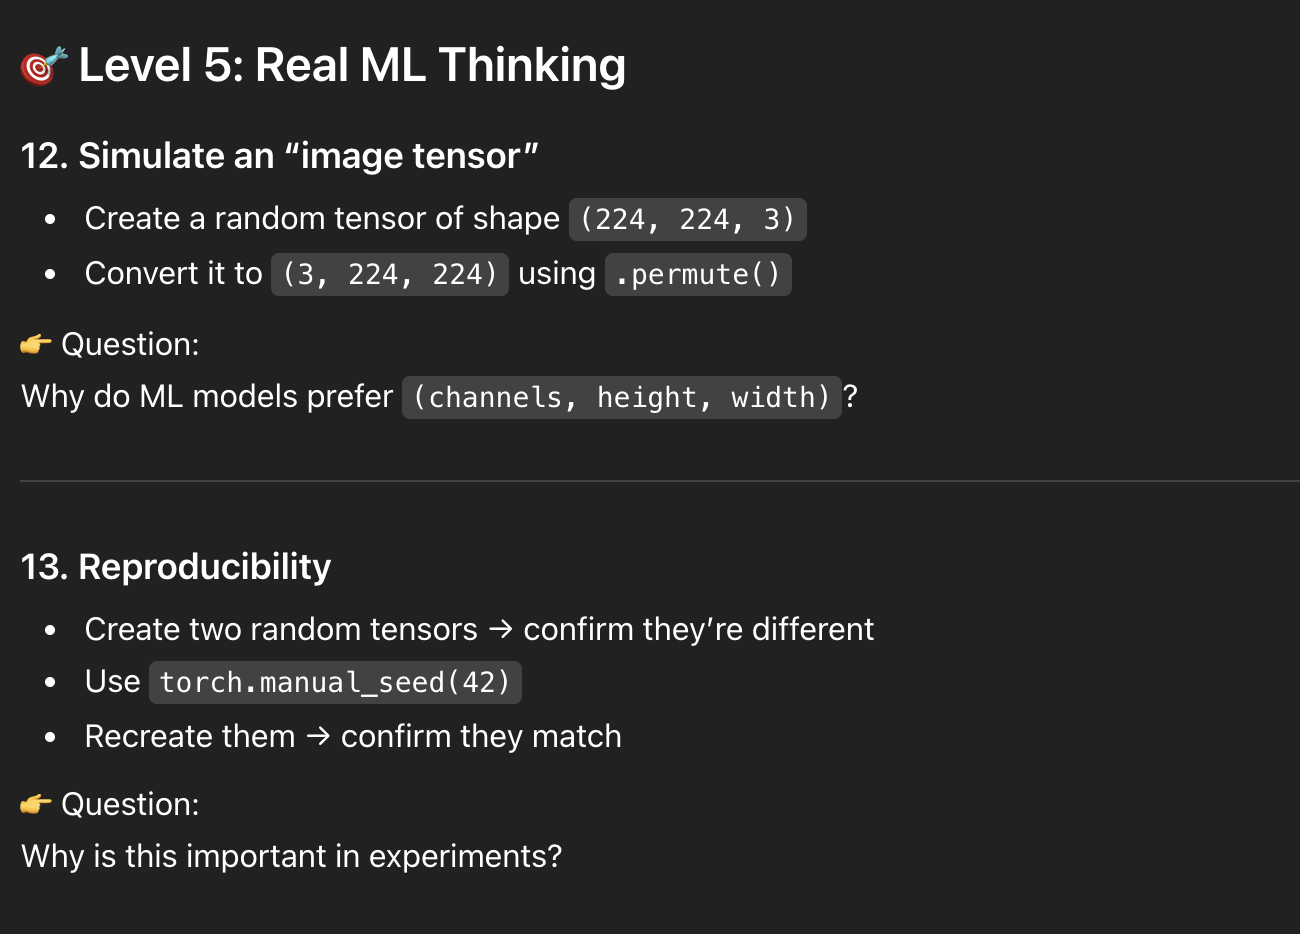

In [ ]:
#12.
torch.manual_seed(8)
random = torch.rand(224, 224, 3)
print(random.shape)

torch.Size([224, 224, 3])


In [ ]:
random = torch.permute(random, (2, 0, 1))
print(random.shape)

torch.Size([3, 224, 224])


In [ ]:
A = torch.rand([8, 2])
B = torch.rand([8, 2])
print(A==B)

tensor([[False, False],
        [False, False],
        [False, False],
        [False, False],
        [False, False],
        [False, False],
        [False, False],
        [False, False]])


In [ ]:
torch.manual_seed(42)
A = torch.rand([8, 2])

torch.manual_seed(42)
B = torch.rand([8, 2])
print(A==B)

tensor([[True, True],
        [True, True],
        [True, True],
        [True, True],
        [True, True],
        [True, True],
        [True, True],
        [True, True]])


In [ ]:
#This brekas in 2 different ways
A = torch.rand(2, 3)
B = torch.rand(2, 3)

C = torch.matmul(A, B)
#debug it

RuntimeError: mat1 and mat2 shapes cannot be multiplied (2x3 and 2x3)

In [ ]:
B = B.reshape(3,2)
C = torch.matmul(A, B)